# From Gaussian noise to handwritten digits
Follow eight noise samples through one ALD-SC reverse-diffusion run. Each tile stays with the same sample throughout. Every frame is decoded into pixels by the trained graph VAE; the GIF plays the actual sampler states, not an interpolation between two pictures.

Run all cells on CPU with the repository kernel. From the root: `uv run --locked --group notebooks jupyter execute notebooks/09_generation_filmstrip.ipynb --inplace --timeout=900`. No checkpoint or GPU is needed. The preview is embedded below; the PNG sequence, GIF and run details are also written to `docs/examples/digit-generation/`.

In [1]:
from pathlib import Path
import gzip, hashlib, io, json, sys
from urllib.request import urlopen
import numpy as np
import torch
from PIL import Image, ImageDraw
from IPython.display import Image as InlineImage, display
from torch.utils.data import DataLoader, TensorDataset

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src/ald_sc').is_dir())
sys.path.insert(0, str(root / 'src'))
from ald_sc import ALDSCLoss, CosineSchedule, MinimalDiT, SpectralVAE, build_arrow_prior
from ald_sc.sampling import sample_ddim, sample_ddim_steps
from ald_sc.trainer import train_vae

seed = 3407
torch.manual_seed(seed)
torch.set_num_threads(2)
torch.use_deterministic_algorithms(True)
out = root / 'docs/examples/digit-generation'
frames_dir = out / 'frames'
frames_dir.mkdir(parents=True, exist_ok=True)

## 1 · A small, real image collection
We use the 1,797-image **Optical Recognition of Handwritten Digits** collection (E. Alpaydin and C. Kaynak, [UCI](https://doi.org/10.24432/C50P49)), as distributed by scikit-learn. The 64 features are an 8 × 8 grid of ink counts, from 0 to 16. This is a new example-level split of that collection, not UCI's original train/test experiment. Labels are not model inputs.

For offline use, place the scikit-learn `digits.csv.gz` file at `.cache/ald-sc/digits.csv.gz` in the project. Otherwise this cell retrieves the same versioned file once. Both paths check the SHA-256 of the decompressed CSV.

In [2]:
url = 'https://raw.githubusercontent.com/scikit-learn/scikit-learn/1.5.2/sklearn/datasets/data/digits.csv.gz'
digest = '6ebb3d2fee246a4e99363262ddf8a00a3c41bee6014c373ed9d9216ba7f651b8'
cache = root / '.cache/ald-sc/digits.csv.gz'
if cache.is_file():
    packed = cache.read_bytes()
else:
    with urlopen(url, timeout=30) as response:
        packed = response.read()
csv = gzip.decompress(packed)
if hashlib.sha256(csv).hexdigest() != digest:
    raise ValueError('Unexpected digits.csv contents; check the data source.')
if not cache.exists():
    cache.parent.mkdir(parents=True, exist_ok=True)
    cache.write_bytes(packed)
rows = np.loadtxt(io.BytesIO(csv), delimiter=',', dtype=np.float32)
assert rows.shape == (1797, 65)
images = torch.from_numpy(rows[:, :64].copy()).reshape(-1, 1, 8, 8) / 8 - 1
order = torch.randperm(len(images), generator=torch.Generator().manual_seed(seed))
train, held_out = images[order[:1440]], images[order[1440:]]
print(f'{len(train)} training images, {len(held_out)} held out; model resolution: 8 × 8')

1440 training images, 357 held out; model resolution: 8 × 8


## 2 · Learn the image decoder
Pool each training image to a 4 × 4 ink map. Its 16 locations supply the feature columns for the frozen graph; eight smooth modes enter the chart. Train the one-channel VAE with the heat gate. As a sanity check, compare held-out posterior-mean reconstruction against always emitting the mean training image. This error measures **reconstruction**, not sample quality.

In [3]:
ink = torch.nn.functional.avg_pool2d((train + 1) / 2, 2).flatten(1)
prior = build_arrow_prior(ink, q=8, k=4)
vae = SpectralVAE(prior, in_channels=1, feature_dim=16, base_channels=16, latent_channels=8, gate_kind='heat')
loader = DataLoader(TensorDataset(train), batch_size=48, shuffle=True, generator=torch.Generator().manual_seed(seed))
vae_epochs = 24
objective = ALDSCLoss(prior, lambda_chart=0, lambda_smooth=0.02, lambda_kl=0.01)
for update in train_vae(loader, vae, prior, objective, epochs=vae_epochs, lr=0.001):
    pass
vae.requires_grad_(False).eval()
with torch.no_grad():
    _, features, means, _ = vae.encode(held_out)
    recon = vae.decode(means, prior.chart_energy_descriptor(features), prior)
    recon_mae = ((recon - held_out).abs().mean() / 2).item()
    baseline_mae = ((train.mean(0) - held_out).abs().mean() / 2).item()
print(f'Held-out MAE (unit intensity): VAE {recon_mae:.4f}; mean-image baseline {baseline_mae:.4f}')

Held-out MAE (unit intensity): VAE 0.0581; mean-image baseline 0.1924


## 3 · Learn to remove noise in latent space
For this small CPU example we cache the trained encoder's posterior **means** and chart descriptors for the training split. Standardise each latent channel using training statistics. The ALD-SC transformer learns to predict velocity at random noise levels with the repository's cosine schedule. Sampling reverses the same standardisation before each decode.

In [4]:
with torch.no_grad():
    batches = [vae.encode(x) for x in train.split(128)]
    means = torch.cat([b[2] for b in batches])
    charts = prior.chart_energy_descriptor(torch.cat([b[1] for b in batches]))
    centre = means.mean((0, 2, 3), keepdim=True)
    scale = means.std((0, 2, 3), keepdim=True).clamp_min(1e-6)
    codes = (means - centre) / scale
schedule = CosineSchedule(num_steps=24)
dit = MinimalDiT(latent_channels=8, latent_size=2, patch_size=1, dim=64, depth=2, num_heads=4, text_dim=0, spec_dim=24)
opt = torch.optim.AdamW(dit.parameters(), lr=0.001)
diffusion_updates = 1800
for step in range(diffusion_updates):
    idx = torch.randint(len(train), (64,))
    z = codes[idx]
    t = schedule.sample_batch(z)
    noise = torch.randn_like(z)
    velocity = dit(schedule.add_noise(z, t, noise), t, c_spec=charts[idx])
    loss = (velocity - schedule.v_target(z, t, noise)).square().mean()
    opt.zero_grad(set_to_none=True)
    loss.backward()
    opt.step()
dit.eval(); print(f'{diffusion_updates} denoiser updates; last minibatch velocity MSE {loss.item():.4f}')

1800 denoiser updates; last minibatch velocity MSE 0.6899


## 4 · Watch eight samples emerge
Use the first eight training charts in the fixed shuffle, one per tile. The **spatial latents start as fresh Gaussian noise**; no image latent or reference pixels are supplied. This is chart-conditioned generation, not the held-out reconstructions above. The first frame decodes noise, the last decodes timestep zero. A shared greyscale and nearest-neighbour enlargement preserve the model's 8 × 8 output. The counter denotes a diffusion step, not motion in a video.

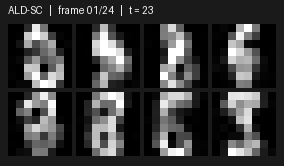

24 PNG frames and a verified looping GIF in docs/examples/digit-generation


In [5]:
args = dict(c_spec=charts[:8], batch_size=8, steps=24, seed=seed)
times = schedule.sample_sigmas(args['steps']).tolist()
with torch.inference_mode():
    latents = list(sample_ddim_steps(dit, schedule, **args))
    endpoint = sample_ddim(dit, schedule, **args)
    torch.testing.assert_close(latents[-1], endpoint)
    decoded = torch.stack([vae.decode(z * scale + centre, charts[:8], prior) for z in latents])
assert torch.isfinite(decoded).all() and times[-1] == 0
pixels = ((decoded.squeeze(2).clamp(-1, 1) + 1) * 127.5).round().byte().numpy()
assert np.any(pixels[0] != pixels[-1])
frames = []
for i, (batch, t) in enumerate(zip(pixels, times, strict=True)):
    frame = Image.new('L', (284, 166), color=26)
    draw = ImageDraw.Draw(frame)
    draw.text((8, 4), f'ALD-SC   |   frame {i + 1:02d}/{len(times)}   |   t = {t:02d}', fill=245)
    for j, tile in enumerate(batch):
        frame.paste(Image.fromarray(tile).resize((64, 64), Image.Resampling.NEAREST), (8 + (j % 4)*68, 24 + (j // 4)*68))
    frame.save(frames_dir / f'frame-{i:03d}.png')
    frames.append(frame)
gif = out / 'generation.gif'
frames[0].save(gif, save_all=True, append_images=frames[1:], duration=[130]*(len(frames)-1)+[1200], loop=0, optimize=False)
with Image.open(gif) as playback:
    assert playback.n_frames == len(times)
    for i, expected in enumerate(frames):
        playback.seek(i)
        assert np.array_equal(np.asarray(playback.convert('L')), np.asarray(expected))
receipt = dict(dataset=url, csv_sha256=digest, seed=seed, train=len(train), held_out=len(held_out), vae_epochs=vae_epochs,
               diffusion_updates=diffusion_updates, gate='heat', condition_dataset_rows=order[:8].tolist(), timesteps=times,
               held_out_reconstruction_mae=recon_mae, mean_image_mae=baseline_mae, torch=str(torch.__version__),
               gif_sha256=hashlib.sha256(gif.read_bytes()).hexdigest(), frames=[f'frames/frame-{i:03d}.png' for i in range(len(times))])
(out / 'run.json').write_text(json.dumps(receipt, indent=2) + '\n')
display(InlineImage(data=gif.read_bytes(), format='gif'))
print(f'{len(frames)} PNG frames and a verified looping GIF in {out.relative_to(root)}')